In [1]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.linalg import helmert

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

In [2]:
DATA_DIR = Path("experiment/data")
RESULTS_DIR = Path("analysis")
RESULTS_DIR.mkdir(exist_ok=True)
CONDITIONS = ["N", "B400", "B1000"]
LABELS = {"N": "N", "B400": "B-400", "B1000": "B-1000"}
MARKERS = {"N": ("^", "black"), "B400": ("s", "white"), "B1000": ("o", "white")}
DEPARTURES = [0, 60, 120, 180]
ORIENTATIONS = [0, 60, 120, 180, 240, 300]
VERSIONS = ["normal", "backward"]
CHARACTERS = ["G", "J", "R", "2", "5", "7"]

In [3]:
def is_autopilot(csv_file):
    info = csv_file.with_name(csv_file.stem + "-info.txt")
    return info.exists() and "AUTOPILOT" in info.read_text(encoding="utf-8", errors="ignore")


def load_sessions(folder):
    files = [f for f in sorted(folder.glob("Mental-Rotation-Preparation_sub-*.csv")) if not is_autopilot(f)]
    if not files:
        return pd.DataFrame()
    return pd.concat([pd.read_csv(f).assign(file=f.name) for f in files], ignore_index=True)

In [4]:
EXAMPLE_MEAN_RT = {
    "N": [570, 665, 800, 1075],
    "B400": [440, 460, 580, 825],
    "B1000": [395, 400, 435, 435],
}


def simulate_sessions(n_subjects=12, seed=1973):
    rng = np.random.default_rng(seed)
    frame_ms = 1000 / 60
    rows = []
    for subject in rng.choice(np.arange(100000, 1000000), n_subjects, replace=False):
        speed = rng.normal(1, 0.1)
        offset = rng.normal(0, 40)
        order = list(rng.permutation(CONDITIONS))
        for block_index, condition in enumerate(order + order[::-1], start=1):
            trials = []
            for departure in DEPARTURES:
                for version in VERSIONS:
                    for rep in range(3):
                        clockwise = departure in (0, 180) or (rep + block_index) % 2 == 0
                        trials.append((departure, version, departure if clockwise else (360 - departure) % 360))
            trials = [trials[i] for i in rng.permutation(len(trials))]
            for trial_in_block, (departure, version, orientation) in enumerate(trials, start=1):
                mean = EXAMPLE_MEAN_RT[condition][DEPARTURES.index(departure)] + (70 if version == "backward" else 0)
                rt = max(250.0, mean * speed + offset + rng.normal(0, 70) + rng.exponential(60) - 60)
                timeout = rt > 3000
                p_correct = 0.97 - 0.05 * departure / 180 - (0.02 if condition == "N" else 0)
                correct = (not timeout) and rng.random() < p_correct
                other = "backward" if version == "normal" else "normal"
                planned = {"N": np.nan, "B400": 400, "B1000": 1000}[condition]
                measured = np.nan if np.isnan(planned) else round(planned / frame_ms) * frame_ms + frame_ms * (rng.random() < 0.02)
                rows.append({
                    "subject_id": subject,
                    "practice": 0,
                    "block_index": block_index,
                    "trial_in_block": trial_in_block,
                    "condition": condition,
                    "cue_ms_planned": planned,
                    "character": rng.choice(CHARACTERS),
                    "version": version,
                    "orientation_deg": orientation,
                    "angular_departure": departure,
                    "response": "none" if timeout else (version if correct else other),
                    "correct": int(correct),
                    "timeout": int(timeout),
                    "rt_ms": np.nan if timeout else round(rt, 3),
                    "arrow_ms_measured": measured,
                    "frame_ms": frame_ms,
                })
    return pd.DataFrame(rows)

In [5]:
sessions = load_sessions(DATA_DIR)
source = str(DATA_DIR)
if sessions.empty:
    sessions = simulate_sessions()
    source = "example data (simulated)"

description = pd.Series({
    "source": source,
    "participants": sessions["subject_id"].nunique(),
    "trials": len(sessions),
})
description.to_csv(RESULTS_DIR / "data_source.csv", header=["value"])
print(description.to_string())
sessions.head()

source          example data (simulated)
participants                          12
trials                              1728


,subject_id,practice,block_index,trial_in_block,condition,cue_ms_planned,character,version,orientation_deg,angular_departure,response,correct,timeout,rt_ms,arrow_ms_measured,frame_ms
0,151597,0,1,1,B1000,1000.0,J,normal,300,60,normal,1,0,352.783,1000.0,16.667
1,151597,0,1,2,B1000,1000.0,7,normal,60,60,normal,1,0,250.000,1000.0,16.667
2,151597,0,1,3,B1000,1000.0,7,normal,180,180,normal,1,0,293.831,1000.0,16.667
3,151597,0,1,4,B1000,1000.0,R,backward,240,120,backward,1,0,539.741,1000.0,16.667
4,151597,0,1,5,B1000,1000.0,R,normal,0,0,normal,1,0,250.000,1000.0,16.667


In [6]:
main = sessions[sessions["practice"] == 0].copy()
answered = main[main["timeout"] == 0]
rt_data = answered[(answered["correct"] == 1) & (answered["rt_ms"] >= 150)].copy()

trial_counts = pd.Series({
    "main trials": len(main),
    "timeouts": int(main["timeout"].sum()),
    "errors": int(((main["timeout"] == 0) & (main["correct"] == 0)).sum()),
    "too fast (< 150 ms)": int(((answered["correct"] == 1) & (answered["rt_ms"] < 150)).sum()),
    "trials kept for response times": len(rt_data),
}).to_frame("count")
trial_counts.to_csv(RESULTS_DIR / "trial_counts.csv")
trial_counts

,count
main trials,1728
timeouts,0
errors,97
too fast (< 150 ms),0
trials kept for response times,1631


In [7]:
error_rates = (
    main.assign(error=1 - main["correct"])
    .groupby(["subject_id", "condition", "angular_departure"])["error"].mean()
    .groupby(["condition", "angular_departure"]).mean()
    .unstack()
    .reindex(CONDITIONS)
    .rename(index=LABELS)
)
error_percent = (100 * error_rates).round(1)
error_percent.to_csv(RESULTS_DIR / "error_rates_percent.csv")
error_percent

angular_departure,0,60,120,180
condition,,,,
N,2.8,10.4,3.5,11.8
B-400,2.8,4.9,5.6,4.2
B-1000,4.2,6.2,3.5,7.6


In [8]:
subject_means = (
    rt_data.groupby(["subject_id", "condition", "orientation_deg"])["rt_ms"].mean()
    .reset_index()
)
mean_rt_by_orientation = (
    subject_means.groupby(["condition", "orientation_deg"])["rt_ms"].mean()
    .unstack()
    .reindex(index=CONDITIONS, columns=ORIENTATIONS)
)
mean_rt_by_orientation[360] = mean_rt_by_orientation[0]
mean_rt_by_orientation.rename(index=LABELS).round(1).to_csv(RESULTS_DIR / "mean_rt_by_orientation.csv")
mean_rt_by_orientation.rename(index=LABELS).round(0)

orientation_deg,0,60,120,180,240,300,360
condition,,,,,,,
N,616.0,711.0,852.0,1128.0,851.0,697.0,616.0
B-400,483.0,518.0,612.0,878.0,617.0,506.0,483.0
B-1000,430.0,434.0,483.0,495.0,490.0,434.0,430.0


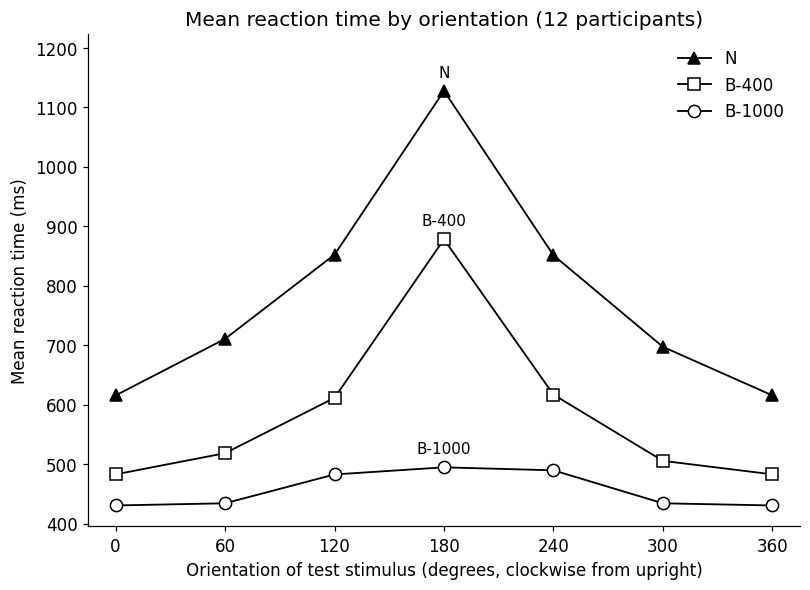

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
x = ORIENTATIONS + [360]
for condition in CONDITIONS:
    marker, face = MARKERS[condition]
    y = mean_rt_by_orientation.loc[condition, x].to_numpy()
    ax.plot(x, y, color="black", linewidth=1.2, marker=marker, markersize=8,
            markerfacecolor=face, markeredgecolor="black", label=LABELS[condition])
    ax.annotate(LABELS[condition], (180, y[3]), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=10)
ax.set_xticks(x)
ax.set_xlim(-15, 375)
ax.set_ylim(top=ax.get_ylim()[1] + 60)
ax.set_xlabel("Orientation of test stimulus (degrees, clockwise from upright)")
ax.set_ylabel("Mean reaction time (ms)")
ax.set_title(f"Mean reaction time by orientation ({sessions['subject_id'].nunique()} participants)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "rt_by_orientation.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
def cell_array(data, dv, subject, factors):
    cells = data.groupby([subject] + factors, observed=True)[dv].mean()
    levels = [sorted(cells.index.get_level_values(name).unique()) for name in [subject] + factors]
    cells = cells.reindex(pd.MultiIndex.from_product(levels, names=[subject] + factors))
    complete = cells.notna().groupby(level=subject).all()
    cells = cells[cells.index.get_level_values(subject).isin(complete[complete].index)]
    shape = [cells.index.get_level_values(subject).nunique()] + [len(level) for level in levels[1:]]
    return cells.to_numpy().reshape(shape)


def sum_of_squares(y, axes):
    effect = 0
    for r in range(len(axes) + 1):
        for kept in combinations(axes, r):
            dropped = tuple(a for a in range(y.ndim) if a not in kept)
            effect = effect + (-1) ** (len(axes) - r) * y.mean(axis=dropped, keepdims=True)
    return float((np.broadcast_to(effect, y.shape) ** 2).sum())


def pooled_error_anova(data, dv, subject, factors, names):
    y = cell_array(data, dv, subject, factors)
    all_axes = tuple(range(y.ndim))
    ss_error = sum_of_squares(y, all_axes)
    df_error = int(np.prod([k - 1 for k in y.shape]))
    rows = []
    for r in range(1, y.ndim):
        for axes in combinations(all_axes, r):
            ss_effect = sum_of_squares(y, axes)
            df_effect = int(np.prod([y.shape[a] - 1 for a in axes]))
            f_value = (ss_effect / df_effect) / (ss_error / df_error)
            rows.append({
                "source": " by ".join(names[a] for a in axes),
                "F": f_value,
                "df": f"{df_effect}, {df_error}",
                "p": stats.f.sf(f_value, df_effect, df_error),
            })
    return pd.DataFrame(rows).set_index("source")

In [11]:
b_conditions = rt_data[rt_data["condition"].isin(["B400", "B1000"])]
paper_anova = pooled_error_anova(
    b_conditions, "rt_ms", "subject_id", ["condition", "orientation_deg", "version"],
    names=["Ss", "Durations", "Orientations", "Versions"],
)
paper_anova.to_csv(RESULTS_DIR / "paper_anova.csv")
paper_anova

,F,df,p
source,,,
Ss,80.767,"11, 55",7.673e-30
Durations,641.024,"1, 55",5.430e-32
Orientations,160.125,"5, 55",1.757e-31
Versions,179.029,"1, 55",6.176e-19
Ss by Durations,1.964,"11, 55",5.051e-02
Ss by Orientations,1.260,"55, 55",1.968e-01
Ss by Versions,0.709,"11, 55",7.251e-01
Durations by Orientations,80.045,"5, 55",5.524e-24
Durations by Versions,1.456,"1, 55",2.327e-01


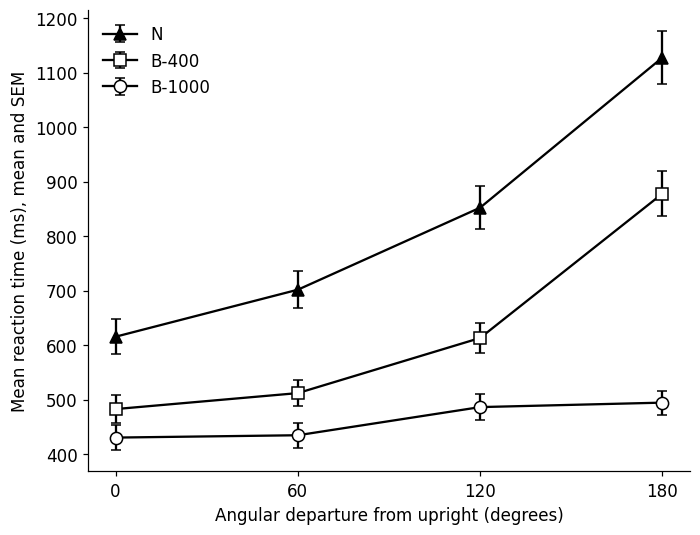

In [12]:
departure_means = (
    rt_data.groupby(["subject_id", "condition", "angular_departure"])["rt_ms"].mean()
    .reset_index()
)
summary = (
    departure_means.groupby(["condition", "angular_departure"])["rt_ms"]
    .agg(["mean", "sem"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(6.5, 5))
for condition in CONDITIONS:
    marker, face = MARKERS[condition]
    part = summary[summary["condition"] == condition]
    ax.errorbar(part["angular_departure"], part["mean"], yerr=part["sem"], color="black",
                marker=marker, markersize=8, markerfacecolor=face, capsize=3, label=LABELS[condition])
ax.set_xticks(DEPARTURES)
ax.set_xlabel("Angular departure from upright (degrees)")
ax.set_ylabel("Mean reaction time (ms), mean and SEM")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "rt_by_departure.png", dpi=150, bbox_inches="tight")
summary.to_csv(RESULTS_DIR / "mean_rt_by_departure.csv", index=False)
plt.show()

In [13]:
def rm_anova(data, dv, subject, factors):
    y = cell_array(data, dv, subject, factors)
    n = y.shape[0]

    def epsilon(axes):
        others = tuple(a for a in range(1, y.ndim) if a not in axes)
        means = (y.mean(axis=others) if others else y).reshape(n, -1)
        contrasts = np.ones((1, 1))
        for a in axes:
            contrasts = np.kron(contrasts, helmert(y.shape[a]))
        if contrasts.shape[0] == 1:
            return 1.0
        cov = np.cov(means @ contrasts.T, rowvar=False)
        return float(np.trace(cov) ** 2 / (contrasts.shape[0] * np.trace(cov @ cov)))

    rows = []
    for r in range(1, len(factors) + 1):
        for axes in combinations(range(1, y.ndim), r):
            ss_effect = sum_of_squares(y, axes)
            ss_error = sum_of_squares(y, (0,) + axes)
            df_effect = int(np.prod([y.shape[a] - 1 for a in axes]))
            df_error = df_effect * (n - 1)
            f_value = (ss_effect / df_effect) / (ss_error / df_error)
            eps = epsilon(axes)
            rows.append({
                "effect": " x ".join(factors[a - 1] for a in axes),
                "df": df_effect,
                "df error": df_error,
                "F": f_value,
                "p": stats.f.sf(f_value, df_effect, df_error),
                "GG epsilon": eps,
                "p (GG)": stats.f.sf(f_value, eps * df_effect, eps * df_error),
                "partial eta2": ss_effect / (ss_effect + ss_error),
            })
    return pd.DataFrame(rows).set_index("effect"), n

In [14]:
anova, n_complete = rm_anova(rt_data, "rt_ms", "subject_id", ["condition", "angular_departure", "version"])
print(f"repeated-measures ANOVA on {n_complete} participants with every cell filled")
anova.to_csv(RESULTS_DIR / "anova.csv")
anova

repeated-measures ANOVA on 12 participants with every cell filled


,df,df error,F,p,GG epsilon,p (GG),partial eta2
effect,,,,,,,
condition,2,22,431.007,2.268e-18,0.565,3.072e-11,0.975
angular_departure,3,33,473.703,3.458e-27,0.603,3.358e-17,0.977
version,1,11,594.866,6.300e-11,1.000,6.300e-11,0.982
condition x angular_departure,6,66,131.825,9.215e-35,0.563,1.624e-20,0.923
condition x version,2,22,2.187,1.361e-01,0.893,1.428e-01,0.166
angular_departure x version,3,33,0.491,6.909e-01,0.739,6.369e-01,0.043
condition x angular_departure x version,6,66,1.481,1.983e-01,0.532,2.351e-01,0.119


In [15]:
departure_effects = pd.DataFrame({
    LABELS[condition]: rm_anova(rt_data[rt_data["condition"] == condition], "rt_ms", "subject_id",
                                ["angular_departure"])[0].loc["angular_departure"]
    for condition in CONDITIONS
}).T
departure_effects.index.name = "condition"
departure_effects.to_csv(RESULTS_DIR / "departure_effect_by_condition.csv")
departure_effects

,df,df error,F,p,GG epsilon,p (GG),partial eta2
condition,,,,,,,
N,3.0,33.0,429.263,1.688e-26,0.625,2.547e-17,0.975
B-400,3.0,33.0,283.980,1.243e-23,0.502,7.160e-13,0.963
B-1000,3.0,33.0,19.321,2.061e-07,0.741,5.539e-06,0.637


In [16]:
def slope(group):
    return np.polyfit(group["angular_departure"], group["rt_ms"], 1)[0]


cell_means = rt_data.groupby(["subject_id", "condition", "angular_departure"])["rt_ms"].mean().reset_index()
slopes = (
    cell_means.groupby(["subject_id", "condition"])[["angular_departure", "rt_ms"]].apply(slope)
    .unstack()
    .reindex(columns=CONDITIONS)
    .dropna()
)

against_zero = pd.DataFrame([
    {
        "condition": LABELS[c],
        "mean slope (ms/deg)": slopes[c].mean(),
        "t": stats.ttest_1samp(slopes[c], 0).statistic,
        "df": len(slopes) - 1,
        "p": stats.ttest_1samp(slopes[c], 0).pvalue,
    }
    for c in CONDITIONS
]).set_index("condition")
slopes.rename(columns=LABELS).to_csv(RESULTS_DIR / "slopes_by_participant.csv")
against_zero.to_csv(RESULTS_DIR / "slopes_against_zero.csv")
against_zero

,mean slope (ms/deg),t,df,p
condition,,,,
N,2.811,24.349,11,6.415e-11
B-400,2.145,18.410,11,1.297e-09
B-1000,0.407,8.677,11,2.993e-06


In [17]:
pairs = list(combinations(CONDITIONS, 2))
comparisons = pd.DataFrame([
    {
        "comparison": f"{LABELS[a]} vs {LABELS[b]}",
        "slope difference (ms/deg)": (slopes[a] - slopes[b]).mean(),
        "t": stats.ttest_rel(slopes[a], slopes[b]).statistic,
        "df": len(slopes) - 1,
        "p": stats.ttest_rel(slopes[a], slopes[b]).pvalue,
    }
    for a, b in pairs
]).set_index("comparison")
order = comparisons["p"].sort_values().index
holm = (comparisons.loc[order, "p"] * np.arange(len(order), 0, -1)).cummax().clip(upper=1)
comparisons["p (Holm)"] = holm.reindex(comparisons.index)
comparisons.to_csv(RESULTS_DIR / "slope_comparisons.csv")
comparisons

,slope difference (ms/deg),t,df,p,p (Holm)
comparison,,,,,
N vs B-400,0.666,7.086,11,2.028e-05,2.028e-05
N vs B-1000,2.404,17.592,11,2.107e-09,6.321e-09
B-400 vs B-1000,1.738,13.941,11,2.458e-08,4.915e-08


In [18]:
version_means = (
    rt_data.groupby(["subject_id", "version"])["rt_ms"].mean()
    .unstack()
    .dropna()
)
difference = version_means["backward"] - version_means["normal"]
test = stats.ttest_rel(version_means["backward"], version_means["normal"])
version_test = pd.Series({
    "mean difference (ms)": difference.mean(),
    "SD (ms)": difference.std(),
    "t": test.statistic,
    "df": len(difference) - 1,
    "p": test.pvalue,
}, name="mirror-image minus normal").to_frame()
version_test.to_csv(RESULTS_DIR / "normal_vs_mirror.csv")
version_test

,mirror-image minus normal
mean difference (ms),6.876e+01
SD (ms),1.616e+01
t,1.474e+01
df,1.100e+01
p,1.369e-08


In [19]:
arrow = main[main["condition"].isin(["B400", "B1000"])].dropna(subset=["arrow_ms_measured"])
arrow = arrow.assign(deviation_ms=arrow["arrow_ms_measured"] - arrow["cue_ms_planned"])
arrow_timing = arrow.groupby("condition")[["cue_ms_planned", "arrow_ms_measured", "deviation_ms"]].agg(["mean", "std", "max"]).reindex(["B400", "B1000"]).rename(index=LABELS)
arrow_timing.to_csv(RESULTS_DIR / "arrow_timing.csv")
arrow_timing

cue_ms_planned              arrow_ms_measured                   \
                    mean  std     max              mean    std       max   
condition                                                                  
B-400              400.0  0.0   400.0           400.434  2.657   416.667   
B-1000            1000.0  0.0  1000.0          1000.289  2.179  1016.667   

          deviation_ms                 
                  mean    std     max  
condition                              
B-400            0.434  2.657  16.667  
B-1000           0.289  2.179  16.667